# Improving the models: regularization, early stopping, and features

This is the next experiment after `01_model_experiments.ipynb`. It tests whether the low scores reflect overly restrictive models, and compares actual training scores with scores on patients held out within CV.

**Reading results:** leave `RUN_OPTIMIZATION=False`. The saved results compare 19 candidate settings × five patient-group folds, including regularization, early stopping, class weighting, and clinical flags. Change it to `True` and run all cells to reproduce those fits plus candidate exports. Early-stopping candidates also perform an internal training fit in each fold.

**Evaluation:** only the original training partition is used for these experiments. No new predictions on the original test set are used for selection. Reusing these development folds for parameter comparisons means the winner's CV score is not an unbiased final performance estimate. The original bagging model remains the deployed-code default.

## 1. Choose the correct kernel
Select **Readmission GCP (Python 3.12)**, restart, and run all cells. This registered kernel includes the Mac OpenMP setting. Explanatory cells are Markdown, not Python.

In [1]:
import os, sys
from pathlib import Path
if sys.version_info < (3, 11):
    raise RuntimeError("Choose the Readmission GCP (Python 3.12) kernel, restart, then Run All.")
ROOT = Path.cwd()
if not (ROOT / "readmission").exists() and (ROOT / "readmission-gcp/readmission").exists():
    ROOT = ROOT / "readmission-gcp"
assert (ROOT / "readmission").exists(), "Run from the readmission-gcp project folder."
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".matplotlib"))
RUN_OPTIMIZATION = False
print("Python:", sys.version.split()[0])
print("Mode:", "new optimization run" if RUN_OPTIMIZATION else "inspect measured optimization results")

Python: 3.12.14
Mode: inspect measured optimization results


In [2]:
"""Training-only model development with grouped CV and inner early stopping.

This module deliberately never scores the previously inspected test partition.
Development CV estimates after parameter search are not unbiased final estimates.
"""
import argparse
import json
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

from readmission.evaluate import metrics
from readmission.features import AUDIT, CATEGORICAL, FEATURES, NUMERIC, SEED, patient_split
from readmission.train import preprocessor


import matplotlib.pyplot as plt
from IPython.display import display
from readmission.optimize import load_training, export_candidate

In [3]:
train_frame = load_training("data/processed/features.csv")
print(f"Training only: {len(train_frame):,} encounters, {train_frame.patient_nbr.nunique():,} patients")
assert set(train_frame.split) == {"train"}

Training only: 51,325 encounters, 38,438 patients


## 2. Check the scaling and correlation advice
Numeric features already use `StandardScaler`, fitted only on the current fold's training patients. We do not add a second scaler. The correlation check below uses training patients only. Correlation alone is not a reason to remove a predictor; coefficient stability and predictive performance are separate questions.

In [4]:
correlation = train_frame[NUMERIC].corr()
correlation_pairs = pd.DataFrame([
    {"feature_1": left, "feature_2": right, "correlation": correlation.loc[left, right]}
    for index, left in enumerate(NUMERIC) for right in NUMERIC[index+1:]
])
display(correlation_pairs.assign(abs_r=lambda f: f.correlation.abs()).sort_values("abs_r", ascending=False).head(8))

,feature_1,feature_2,correlation,abs_r
2,time_in_hospital,num_medications,0.459919,0.459919
13,num_procedures,num_medications,0.376275,0.376275
0,time_in_hospital,num_lab_procedures,0.324717,0.324717
8,num_lab_procedures,num_medications,0.275705,0.275705
21,num_medications,number_diagnoses,0.267033,0.267033
25,number_emergency,number_inpatient,0.258731,0.258731
6,time_in_hospital,number_diagnoses,0.204026,0.204026
1,time_in_hospital,num_procedures,0.170507,0.170507


## 3. Declare the parameter comparisons
For LR, increasing `C` weakens regularization. The first sweep checks C=0.5, 1, 10, 100. The follow-up also checks stronger regularization at C=0.1 and 0.01 because the weaker settings worsened CV.

XGBoost experiments separate more trees/early stopping from additional flexibility. Early stopping uses up to 1,500 trees, learning rate 0.03, and patience 50, monitoring XGBoost's `aucpr`. Final comparisons use scikit-learn average precision; these are related but distinct measures. Depth 6/8 and smaller minimum child weight test more flexible rules.

In [5]:
def candidate_specs():
    """A small, declared sweep rather than unbounded tuning."""
    specs = [
        {"name": f"lr_C_{c:g}", "family": "lr", "C": c, "early_stopping": False}
        for c in [0.5, 1.0, 10.0, 100.0]
    ]
    specs += [
        {"name": "xgb_original", "family": "xgb", "learning_rate": 0.05,
         "n_estimators": 300, "max_depth": 4, "min_child_weight": 20, "reg_lambda": 5,
         "early_stopping": False},
        {"name": "xgb_more_trees", "family": "xgb", "learning_rate": 0.03,
         "n_estimators": 1500, "max_depth": 4, "min_child_weight": 20, "reg_lambda": 5,
         "early_stopping": True},
        {"name": "xgb_flexible", "family": "xgb", "learning_rate": 0.03,
         "n_estimators": 1500, "max_depth": 6, "min_child_weight": 5, "reg_lambda": 1,
         "early_stopping": True},
        {"name": "xgb_deeper", "family": "xgb", "learning_rate": 0.03,
         "n_estimators": 1500, "max_depth": 8, "min_child_weight": 1, "reg_lambda": 1,
         "early_stopping": True},
    ]
    return specs

def followup_specs():
    return [
        {"name": "lr_C_0.01", "family": "lr", "C": 0.01, "early_stopping": False},
        {"name": "lr_C_0.1", "family": "lr", "C": 0.1, "early_stopping": False},
        {"name": "lr_engineered", "family": "lr", "C": 0.5, "early_stopping": False, "engineered_features": True},
        {"name": "xgb_engineered", "family": "xgb", "learning_rate": 0.05,
         "n_estimators": 300, "max_depth": 4, "min_child_weight": 20, "reg_lambda": 5,
         "early_stopping": False, "engineered_features": True},
    ]

def imbalance_specs():
    xgb_base = {"family": "xgb", "learning_rate": 0.05, "n_estimators": 300,
                "max_depth": 4, "min_child_weight": 20, "reg_lambda": 5, "early_stopping": False}
    return [
        {"name": "lr_balanced_C_0.01", "family": "lr", "C": 0.01, "early_stopping": False, "class_weight": "balanced"},
        {"name": "lr_balanced_C_0.1", "family": "lr", "C": 0.1, "early_stopping": False, "class_weight": "balanced"},
        {**xgb_base, "name": "xgb_positive_weight_2", "scale_pos_weight": 2.0},
        {**xgb_base, "name": "xgb_positive_weight_ratio", "scale_pos_weight": "ratio"},
        {**xgb_base, "name": "xgb_comorbidity_flags", "comorbidity_flags": True},
        {**xgb_base, "name": "xgb_weighted_comorbidities", "comorbidity_flags": True, "scale_pos_weight": "ratio"},
        {"name": "lr_comorbidity_flags", "family": "lr", "C": 0.01, "early_stopping": False, "comorbidity_flags": True},
    ]

display(pd.DataFrame(candidate_specs() + followup_specs() + imbalance_specs()).fillna('—'))

,name,family,C,early_stopping,learning_rate,n_estimators,max_depth,min_child_weight,reg_lambda,engineered_features,class_weight,scale_pos_weight,comorbidity_flags
0,lr_C_0.5,lr,0.5,False,—,—,—,—,—,—,—,—,—
1,lr_C_1,lr,1.0,False,—,—,—,—,—,—,—,—,—
2,lr_C_10,lr,10.0,False,—,—,—,—,—,—,—,—,—
3,lr_C_100,lr,100.0,False,—,—,—,—,—,—,—,—,—
4,xgb_original,xgb,—,False,0.05,300.0,4.0,20.0,5.0,—,—,—,—
5,xgb_more_trees,xgb,—,True,0.03,1500.0,4.0,20.0,5.0,—,—,—,—
6,xgb_flexible,xgb,—,True,0.03,1500.0,6.0,5.0,1.0,—,—,—,—
7,xgb_deeper,xgb,—,True,0.03,1500.0,8.0,1.0,1.0,—,—,—,—
8,lr_C_0.01,lr,0.01,False,—,—,—,—,—,—,—,—,—
9,lr_C_0.1,lr,0.1,False,—,—,—,—,—,—,—,—,—


## 4. Test a small set of derived features
The follow-up compares original features with additional visit-history totals, nonlinear logged visit counts, medication-status counts, medications per stay-day, and broad diagnosis groups. This first ablation tests them as a bundle; it does not identify which individual feature helped.

Groups follow broad ICD-9 chapter ranges, with diabetes (250) separate. These are coarse modeling groups, not an ICD-10 conversion or a validated comorbidity index. [CMS chapter definitions](https://www.cms.gov/research-statistics-data-and-systems/statistics-trends-and-reports/bsapufs/downloads/2008_bsa_outpatient_procedure_puf_datadic_cbpdf), [CDC diagnosis-group reference](https://www.cdc.gov/nchs/data/ad/ad389.pdf).

All derived information is available by discharge. Outcomes, identifiers, and future records are excluded.

In [6]:
DERIVED_NUMERIC = ["prior_total_visits", "prior_acute_visits", "any_prior_inpatient",
                   "active_diabetes_medications", "changed_diabetes_medications", "medications_per_day",
                   "log_prior_inpatient", "log_prior_emergency", "log_prior_outpatient"]
DERIVED_CATEGORICAL = ["diag_1_group", "diag_2_group", "diag_3_group"]
CLINICAL_FLAGS = ["coded_diabetes_250", "coded_heart_failure_428", "coded_ckd_585"]



def diagnosis_group(value):
    value = str(value)
    if value.startswith("V"):
        return "supplementary"
    if value.startswith("E"):
        return "external_causes"
    try:
        number = float(value)
    except ValueError:
        return "missing_or_unmapped"
    if 250 <= number < 251:
        return "diabetes"
    boundaries = [(1, 140, "infectious"), (140, 240, "neoplasms"), (240, 280, "endocrine"),
                  (280, 290, "blood"), (290, 320, "mental"), (320, 390, "nervous_sensory"),
                  (390, 460, "circulatory"), (460, 520, "respiratory"), (520, 580, "digestive"),
                  (580, 630, "genitourinary"), (630, 680, "pregnancy"), (680, 710, "skin"),
                  (710, 740, "musculoskeletal"), (740, 760, "congenital"),
                  (760, 780, "perinatal"), (780, 800, "symptoms"), (800, 1000, "injury")]
    return next((label for low, high, label in boundaries if low <= number < high), "other")

def derive_features(frame):
    """Deterministic discharge-time features; no outcomes, IDs, or future information."""
    from readmission.features import MEDICATIONS
    result = frame.copy()
    result["prior_total_visits"] = result.number_inpatient + result.number_emergency + result.number_outpatient
    result["prior_acute_visits"] = result.number_inpatient + result.number_emergency
    result["any_prior_inpatient"] = (result.number_inpatient > 0).astype(int)
    result["active_diabetes_medications"] = result[MEDICATIONS].isin(["Steady", "Up", "Down"]).sum(axis=1)
    result["changed_diabetes_medications"] = result[MEDICATIONS].isin(["Up", "Down"]).sum(axis=1)
    result["medications_per_day"] = result.num_medications / result.time_in_hospital.clip(lower=1)
    for name in ["inpatient", "emergency", "outpatient"]:
        result[f"log_prior_{name}"] = np.log1p(result[f"number_{name}"])
    for name in ["diag_1", "diag_2", "diag_3"]:
        result[f"{name}_group"] = result[name].map(diagnosis_group)
    diagnosis_numbers = result[["diag_1", "diag_2", "diag_3"]].apply(pd.to_numeric, errors="coerce")
    for name, code in zip(CLINICAL_FLAGS, [250, 428, 585]):
        result[name] = ((diagnosis_numbers >= code) & (diagnosis_numbers < code + 1)).any(axis=1).astype(int)
    return result

In [7]:
# Use the canonical package function in serialized models so they load outside this notebook.
from readmission.optimize import derive_features
example = derive_features(train_frame[FEATURES].head())
display(example[DERIVED_NUMERIC + DERIVED_CATEGORICAL + CLINICAL_FLAGS])

,prior_total_visits,prior_acute_visits,any_prior_inpatient,active_diabetes_medications,changed_diabetes_medications,medications_per_day,log_prior_inpatient,log_prior_emergency,log_prior_outpatient,diag_1_group,diag_2_group,diag_3_group,coded_diabetes_250,coded_heart_failure_428,coded_ckd_585
0,0,0,0,2,0,8.000000,0.0,0.0,0.0,neoplasms,neoplasms,diabetes,1,0,0
1,0,0,0,1,0,1.888889,0.0,0.0,0.0,diabetes,circulatory,injury,1,0,0
2,0,0,0,1,0,5.333333,0.0,0.0,0.0,circulatory,circulatory,diabetes,1,0,0
3,0,0,0,1,0,3.100000,0.0,0.0,0.0,circulatory,circulatory,circulatory,0,1,0
4,0,0,0,1,0,2.000000,0.0,0.0,0.0,respiratory,injury,genitourinary,0,0,0


In [8]:
def feature_transform(spec):
    engineered = spec.get("engineered_features", False)
    flags = spec.get("comorbidity_flags", False)
    if not (engineered or flags):
        return preprocessor()
    numeric = NUMERIC + (DERIVED_NUMERIC if engineered else []) + (CLINICAL_FLAGS if flags else [])
    categorical = CATEGORICAL + (DERIVED_CATEGORICAL if engineered else [])
    transform = ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
        ("categorical", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=25), categorical),
    ], remainder="drop", sparse_threshold=1.0)
    return Pipeline([("derive", FunctionTransformer(derive_features, validate=False)), ("encode", transform)])

def positive_class_weight(spec, fit):
    value = spec.get("scale_pos_weight", 1.0)
    if value == "ratio":
        positive = int(fit.label.sum())
        if not positive:
            raise ValueError("Cannot calculate class ratio without positive examples.")
        return (len(fit) - positive) / positive
    return float(value)

def estimator(spec, n_estimators=None, stopping=False, positive_weight=1.0):
    if spec["family"] == "lr":
        return LogisticRegression(C=spec["C"], class_weight=spec.get("class_weight"), max_iter=2000, random_state=SEED)
    options = dict(
        n_estimators=n_estimators or spec["n_estimators"],
        max_depth=spec["max_depth"], learning_rate=spec["learning_rate"],
        min_child_weight=spec["min_child_weight"], reg_lambda=spec["reg_lambda"],
        subsample=0.85, colsample_bytree=0.85, tree_method="hist",
        random_state=SEED, n_jobs=2, eval_metric="aucpr" if stopping else "logloss",
        scale_pos_weight=positive_weight,
    )
    if stopping:
        options["early_stopping_rounds"] = 50
    return XGBClassifier(**options)

### Class imbalance and specific diagnosis flags
LR's `class_weight='balanced'` is calculated from the current fitting data. XGBoost compares positive weight 1, 2, and the current fit group's negative/positive ratio (roughly 9). Early-stopping fits would use their own inner fitting ratio, not outer holdout outcomes. Weighting may improve discrimination, but does not automatically solve imbalance. Weighted raw probabilities need calibration before interpreting them as readmission risks.

We also test flags indicating ICD-9 250.x (diabetes), 428.x (heart failure), and 585.x (CKD) in the three provided diagnoses. These flags are limited code indicators, not complete validated comorbidity phenotypes; absence of a code does not prove absence of a condition. All encounters are diabetes-associated, so a diabetes-code flag is not a general diabetes diagnosis test.

No SMOTE or other oversampling is performed. Any future oversampling must be restricted to the fitting patients inside each fold. Target encoding would also need training-only fitting and group-aware cross-fitting. [LR class weights](https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html), [XGBoost weights](https://xgboost.readthedocs.io/en/release_2.1.0/parameter.html).

The current diagnosis grouping is a coarse chapter mapping, not CCS/CCSR. The appropriate external taxonomy for these ICD-9 data is [AHRQ CCS for ICD-9-CM](https://hcup-us.ahrq.gov/toolssoftware/ccs/ccs.jsp); CCSR for ICD-10 should not be directly applied. An exact CCS mapping remains a separate experiment.

## 5. Early stopping without using the evaluation patients
For each outer CV fold:

1. Set aside the outer fold's evaluation patients.
2. Split the remaining patients into an inner fit group (85%) and a stopping group (15%).
3. Fit preprocessing on inner fit patients only, then use the stopping group to choose the tree count.
4. Refit preprocessing and the chosen number of trees on all outer-fit patients.
5. Score the outer evaluation patients, who influenced neither preprocessing nor early stopping.

Both group boundaries are checked for patient overlap. Other model settings are selected by comparing outer development CV, so this is not a full nested hyperparameter-search estimate.

In [9]:
def fit_candidate(spec, fit, seed=SEED):
    """Select the tree count using inner patients; refit using all fold-fit patients."""
    metadata = {"inner_patient_overlap": 0, "chosen_trees": None,
                "positive_class_weight": positive_class_weight(spec, fit),
                "inner_fit_patients": None, "inner_stop_patients": None}
    count = None
    if spec["early_stopping"]:
        inner_fit_index, stop_index = next(GroupShuffleSplit(
            n_splits=1, test_size=0.15, random_state=seed
        ).split(fit, fit.label, groups=fit.patient_nbr))
        inner_fit, stop = fit.iloc[inner_fit_index], fit.iloc[stop_index]
        overlap = set(inner_fit.patient_nbr) & set(stop.patient_nbr)
        if overlap:
            raise ValueError("Patient overlap in early-stopping groups.")
        transform = feature_transform(spec)
        fit_x = transform.fit_transform(inner_fit[FEATURES])
        stop_x = transform.transform(stop[FEATURES])
        model = estimator(spec, stopping=True, positive_weight=positive_class_weight(spec, inner_fit))
        model.fit(fit_x, inner_fit.label, eval_set=[(stop_x, stop.label)], verbose=False)
        count = int(model.best_iteration + 1)
        metadata.update(chosen_trees=count, inner_fit_patients=int(inner_fit.patient_nbr.nunique()),
                        inner_stop_patients=int(stop.patient_nbr.nunique()))
    elif spec["family"] == "xgb":
        metadata["chosen_trees"] = spec["n_estimators"]
    pipeline = Pipeline([("features", feature_transform(spec)),
                         ("model", estimator(spec, n_estimators=count, positive_weight=positive_class_weight(spec, fit)))])
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        pipeline.fit(fit[FEATURES], fit.label)
    return pipeline, metadata

## 6. Run or inspect the five-fold experiment
Training scores describe fit to already-seen patients. CV scores describe predictions on held-out patients. A large training-minus-CV gap is evidence that improved fit is failing to transfer. In-sample training scores are not evidence of clinical usefulness.

In [10]:
def diagnostic_scores(frame, scores):
    values = metrics(frame.label, scores)
    return {key: values[key] for key in ["average_precision", "roc_auc", "precision_at_capacity", "recall_at_capacity", "brier_score"]}

def summarize(rows):
    columns = [col for col in rows if col.startswith(("train_", "cv_"))]
    summary = rows.groupby(["candidate", "family"])[columns].agg(["mean", "std"])
    summary.columns = ["_".join(column) for column in summary.columns]
    summary = summary.reset_index()
    summary["ap_gap"] = summary.train_average_precision_mean - summary.cv_average_precision_mean
    return summary.sort_values("cv_average_precision_mean", ascending=False).reset_index(drop=True)

def run_sweep(train_frame, output_dir, specs=None, n_splits=5):
    if "split" not in train_frame or not (train_frame.split == "train").all():
        raise ValueError("The optimization sweep accepts only the training partition.")
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    specs = specs or candidate_specs()
    folds = list(GroupKFold(n_splits=n_splits).split(train_frame[FEATURES], train_frame.label,
                                                   groups=train_frame.patient_nbr))
    rows = []
    spec_lookup = {spec["name"]: spec for spec in specs}
    for spec in specs:
        for number, (fit_index, holdout_index) in enumerate(folds, start=1):
            fit, holdout = train_frame.iloc[fit_index], train_frame.iloc[holdout_index]
            if set(fit.patient_nbr) & set(holdout.patient_nbr):
                raise ValueError("Patient overlap in outer CV.")
            pipeline, metadata = fit_candidate(spec, fit, seed=SEED + number)
            train_scores = pipeline.predict_proba(fit[FEATURES])[:, 1]
            holdout_scores = pipeline.predict_proba(holdout[FEATURES])[:, 1]
            row = {"candidate": spec["name"], "family": spec["family"], "fold": number,
                   "outer_patient_overlap": 0, **metadata,
                   **{f"train_{key}": value for key, value in diagnostic_scores(fit, train_scores).items()},
                   **{f"cv_{key}": value for key, value in diagnostic_scores(holdout, holdout_scores).items()}}
            rows.append(row)
            print(f"{spec['name']} fold {number}/{n_splits}: training AP={row['train_average_precision']:.4f}, CV AP={row['cv_average_precision']:.4f}, trees={metadata['chosen_trees']}", flush=True)
            pd.DataFrame(rows).to_csv(output_dir / "optimization_folds.csv", index=False)
        # Persist summaries after each candidate so results survive an interrupted run.
        summary = summarize(pd.DataFrame(rows))
        summary.to_csv(output_dir / "optimization_summary.csv", index=False)
    selected = str(summary.sort_values("cv_average_precision_mean", ascending=False).iloc[0].candidate)
    results = {
        "created_at_utc": datetime.now(timezone.utc).isoformat(), "selected_candidate": selected,
        "selected_spec": spec_lookup[selected], "selection_metric": "training-only group CV mean average precision",
        "training_encounters": len(train_frame), "training_patients": int(train_frame.patient_nbr.nunique()),
        "candidate_count": len(specs), "cv_folds": n_splits, "candidate_specs": specs,
        "evaluation_status": "development_cv_only_no_test_scoring",
        "limitations": ["Repeated parameter comparisons can overfit the development folds.",
                        "CV variability is not a confidence interval.",
                        "These comparisons do not establish clinically useful performance.",
                        "The original test results were previously inspected and are not an untouched final evaluation."],
    }
    (output_dir / "optimization_metadata.json").write_text(json.dumps(results, indent=2))
    return pd.DataFrame(rows), summary, results

In [11]:
directories = [Path("artifacts/optimization"), Path("artifacts/optimization_followup"), Path("artifacts/optimization_imbalance")]
if RUN_OPTIMIZATION:
    for specs, directory in zip([candidate_specs(), followup_specs(), imbalance_specs()], directories):
        fold_rows, summary, metadata = run_sweep(train_frame, directory, specs=specs)
        export_candidate(train_frame, metadata["selected_spec"], directory)
fold_rows = pd.concat([pd.read_csv(d / "optimization_folds.csv") for d in directories], ignore_index=True)
summary = pd.concat([pd.read_csv(d / "optimization_summary.csv") for d in directories], ignore_index=True)
summary = summary.sort_values("cv_average_precision_mean", ascending=False).reset_index(drop=True)
assert (fold_rows.outer_patient_overlap == 0).all()
assert (fold_rows.inner_patient_overlap == 0).all()
display(summary[["candidate", "train_average_precision_mean", "cv_average_precision_mean", "cv_average_precision_std", "ap_gap"]].round(4))

,candidate,train_average_precision_mean,cv_average_precision_mean,cv_average_precision_std,ap_gap
0,xgb_positive_weight_ratio,0.2611,0.2057,0.0093,0.0554
1,xgb_weighted_comorbidities,0.2623,0.2054,0.0096,0.0569
2,lr_balanced_C_0.01,0.2168,0.2050,0.0147,0.0118
3,xgb_engineered,0.2604,0.2050,0.0128,0.0554
4,xgb_more_trees,0.2278,0.2048,0.0119,0.0230
5,lr_comorbidity_flags,0.2138,0.2046,0.0159,0.0092
6,lr_C_0.01,0.2136,0.2045,0.0157,0.0090
7,xgb_positive_weight_2,0.2559,0.2043,0.0097,0.0516
8,xgb_original,0.2501,0.2038,0.0106,0.0463
9,xgb_comorbidity_flags,0.2514,0.2038,0.0099,0.0476


## 7. Compare precision and recall at the same 10% capacity
Average precision (AP) summarizes the full precision–recall curve; it is not the precision at one cutoff. These columns report the fraction readmitted among the highest-risk 10% (precision) and the fraction of all readmissions found there (recall). We retain the same 10% capacity for model comparisons.

In [12]:
display(summary[["candidate", "train_precision_at_capacity_mean", "train_recall_at_capacity_mean",
                 "cv_precision_at_capacity_mean", "cv_recall_at_capacity_mean"]].round(4))
original = json.loads(Path("artifacts/metrics.json").read_text())
reference = pd.DataFrame([
    {"candidate": name + " (original reference)",
     "cv_average_precision_mean": values["average_precision"]["mean"],
     "cv_precision_at_capacity_mean": values["precision_at_capacity"]["mean"],
     "cv_recall_at_capacity_mean": values["recall_at_capacity"]["mean"]}
    for name, values in original["cross_validation"].items()
])
display(reference.round(4))
best_new = summary.iloc[0]
bagging_ap = original["cross_validation"]["bagged_trees"]["average_precision"]["mean"]
print(f"Best new candidate: {best_new.candidate}, CV AP={best_new.cv_average_precision_mean:.4f}")
print(f"Original bagging reference: CV AP={bagging_ap:.4f}")
print("Small development-score differences do not establish a significant improvement.")

,candidate,train_precision_at_capacity_mean,train_recall_at_capacity_mean,cv_precision_at_capacity_mean,cv_recall_at_capacity_mean
0,xgb_positive_weight_ratio,0.2898,0.2924,0.2425,0.2446
1,xgb_weighted_comorbidities,0.2915,0.2941,0.2421,0.2443
2,lr_balanced_C_0.01,0.2529,0.2552,0.2426,0.2447
3,xgb_engineered,0.2894,0.2920,0.2417,0.2438
4,xgb_more_trees,0.2585,0.2607,0.2393,0.2415
5,lr_comorbidity_flags,0.2487,0.2509,0.2413,0.2434
6,lr_C_0.01,0.2485,0.2507,0.2423,0.2443
7,xgb_positive_weight_2,0.2861,0.2886,0.2434,0.2456
8,xgb_original,0.2808,0.2833,0.2415,0.2436
9,xgb_comorbidity_flags,0.2813,0.2838,0.2405,0.2427


,candidate,cv_average_precision_mean,cv_precision_at_capacity_mean,cv_recall_at_capacity_mean
0,bagged_trees (original reference),0.2058,0.2413,0.2434
1,logistic_regression (original reference),0.1984,0.2403,0.2426
2,xgboost (original reference),0.2038,0.2415,0.2436


Best new candidate: xgb_positive_weight_ratio, CV AP=0.2057
Original bagging reference: CV AP=0.2058
Small development-score differences do not establish a significant improvement.


## 8. Visualize what changed
Higher training scores are helpful only when predictive performance transfers to held-out patients. The plots show why the more complex depth-8 model is not automatically a better candidate.

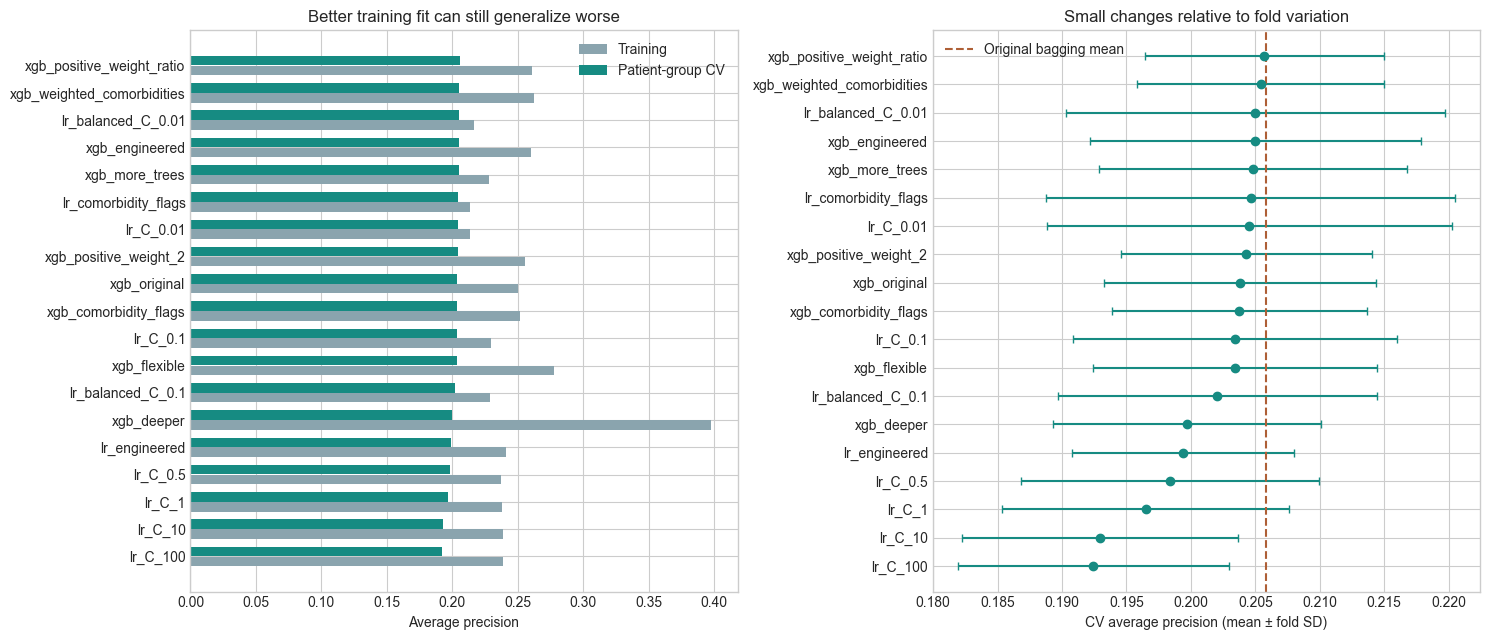

In [13]:
plt.style.use("seaborn-v0_8-whitegrid")
shown = summary.sort_values("cv_average_precision_mean")
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
y = np.arange(len(shown))
axes[0].barh(y-.18, shown.train_average_precision_mean, height=.35, label="Training", color="#8aa4ae")
axes[0].barh(y+.18, shown.cv_average_precision_mean, height=.35, label="Patient-group CV", color="#168b82")
axes[0].set(yticks=y, yticklabels=shown.candidate, xlabel="Average precision", title="Better training fit can still generalize worse")
axes[0].legend()
axes[1].errorbar(shown.cv_average_precision_mean, y, xerr=shown.cv_average_precision_std,
                 fmt="o", color="#168b82", capsize=3)
axes[1].axvline(bagging_ap, color="#ae5f36", linestyle="--", label="Original bagging mean")
axes[1].set(yticks=y, yticklabels=shown.candidate, xlabel="CV average precision (mean ± fold SD)", title="Small changes relative to fold variation")
axes[1].legend()
fig.tight_layout()
fig.savefig("artifacts/optimization/optimization_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Understand selection size separately from model quality
This uses the original model's already-saved test predictions as an explanatory reference. It does not score a new candidate or tune its settings against test outcomes. Choosing more patients is a change in the outreach policy, not an improvement in the model. Keep capacity fixed when comparing models.

In [14]:
saved_test = pd.read_csv("artifacts/test_predictions.csv")
capacities = []
for capacity in [.05, .10, .20, .30, .50]:
    values = metrics(saved_test.label, saved_test.predicted_risk, capacity)
    capacities.append({"selected_fraction": capacity, "precision": values["precision_at_capacity"],
                       "recall": values["recall_at_capacity"], "selected": values["outreach_count"]})
capacity_table = pd.DataFrame(capacities)
display(capacity_table.round(4))
capacity_table.to_csv("artifacts/optimization/original_model_capacity_reference.csv", index=False)

,selected_fraction,precision,recall,selected
0,0.05,0.2928,0.1460,543
1,0.10,0.2505,0.2498,1086
2,0.20,0.1989,0.3967,2172
3,0.30,0.1694,0.5069,3258
4,0.50,0.1391,0.6933,5429


## 10. Findings and useful next experiments
**Initial findings before the imbalance experiment:** weaker LR regularization did not help; stronger regularization improved LR's development AP. More trees with early stopping modestly helped the original XGBoost setup. Depth-8 trees increased training fit but worsened CV. The first engineered-feature bundle produced a small XGBoost gain. Use the complete comparison table above to assess whether class weights or specific diagnosis flags improve these results.

**Next suggestions:**
- Test the derived features separately to find which ones help, instead of assuming the whole bundle is useful.
- Test the omitted medical-specialty and payer fields with explicit missing categories. Missingness alone does not prove a field is useless; check predictive gains and subgroup behavior.
- Plot learning curves using patient groups to see whether additional examples improve held-out performance.
- If 10% outreach capacity is the actual decision, define that objective before another search; compare its recall alongside AP.
- For a credible final result, obtain an independent dataset or use a properly nested evaluation; the inspected original test partition cannot become untouched again.

Saved candidate files are **uncalibrated development models**. They are not installed into the original prediction service. The original calibrated model, comparison, and GCP scripts remain available.